# Кластеризация клиентов German Credit с DBSCAN

Цель — исследовать группы клиентов по их характеристикам и выделить наблюдения,
которые DBSCAN считает шумом. Метки кредитного риска в этом файле нет.

Запускайте ячейки сверху вниз из папки с `german_credit_data.csv`.
Если зависимости отсутствуют, выполните в отдельной ячейке:
`%pip install numpy pandas matplotlib seaborn scikit-learn gower`.

Сначала изучим данные, затем построим матрицу расстояний Гауэра, подберём
`eps` и `min_samples`, визуализируем и опишем результат.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gower

from IPython.display import display, Markdown
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [3]:
df = pd.read_csv("german_credit_data.csv")

# В датасете есть техническая колонка с индексом — убираем
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

print(df.shape)
df.head()

(1000, 9)


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,67,male,2,own,NaN,little,1169,6,radio/TV
1,22,female,2,own,little,moderate,5951,48,radio/TV
2,49,male,1,own,little,NaN,2096,12,education
3,45,male,2,free,little,little,7882,42,furniture/equipment
4,53,male,2,free,little,little,4870,24,car


In [4]:
df.info()
df.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Age               1000 non-null   int64
 1   Sex               1000 non-null   str  
 2   Job               1000 non-null   int64
 3   Housing           1000 non-null   str  
 4   Saving accounts   817 non-null    str  
 5   Checking account  606 non-null    str  
 6   Credit amount     1000 non-null   int64
 7   Duration          1000 non-null   int64
 8   Purpose           1000 non-null   str  
dtypes: int64(4), str(5)
memory usage: 70.4 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1000.0,NaN,NaN,NaN,35.546,11.375469,19.0,27.0,33.0,42.0,75.0
Sex,1000,2,male,690,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job,1000.0,NaN,NaN,NaN,1.904,0.653614,0.0,2.0,2.0,2.0,3.0
Housing,1000,3,own,713,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Saving accounts,817,4,little,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Checking account,606,3,little,274,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Credit amount,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Duration,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
Purpose,1000,8,car,337,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Пропуски
df.isna().sum()

Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
dtype: int64

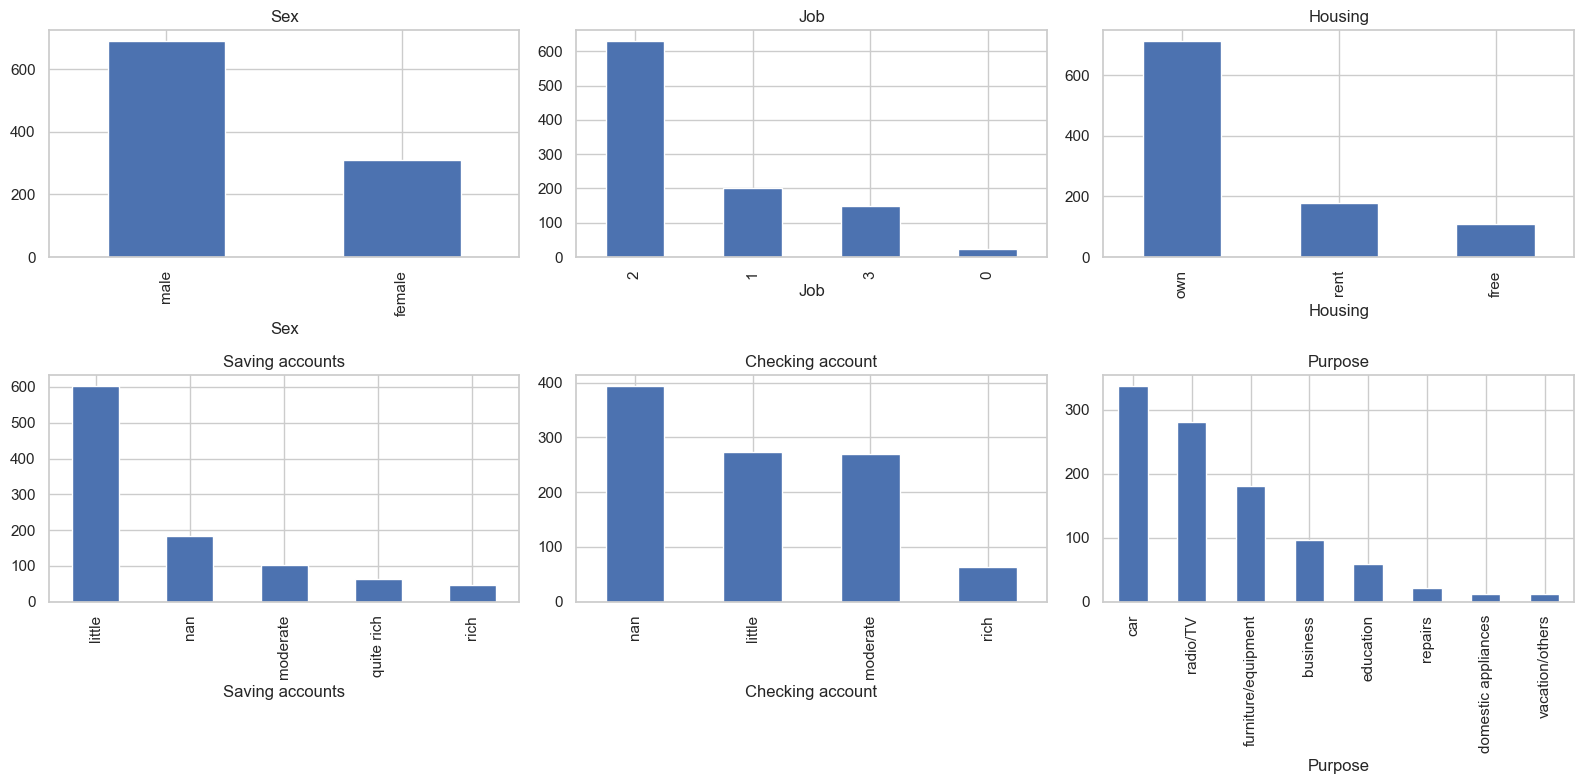

In [6]:
# Категориальные признаки
cat_cols = ["Sex", "Job", "Housing", "Saving accounts",
            "Checking account", "Purpose"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flatten(), cat_cols):
    df[col].value_counts(dropna=False).plot(kind="bar", ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

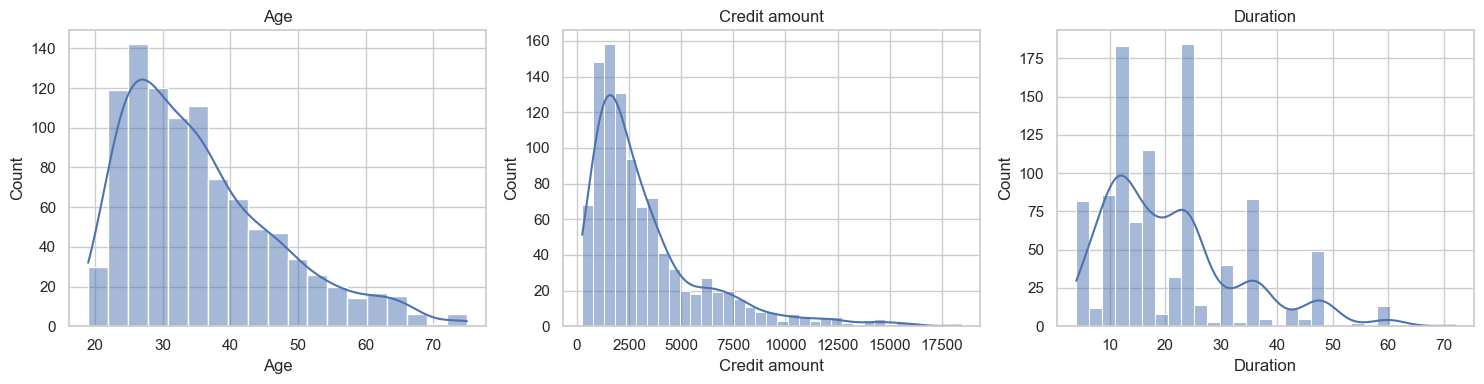

In [7]:
# Распределения числовых признаков
num_cols = ["Age", "Credit amount", "Duration"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Подготовка смешанных признаков

`Job` — код категории, поэтому обрабатываем его вместе с остальными
категориальными признаками. Пропуски в категориях заменяем отдельным значением
`Unknown`: это допущение об отсутствии информации, а не утверждение, что счёта нет.
В числовых признаках при необходимости используем медиану.

Расстояние Гауэра усредняет различия по признакам: числовые различия нормируются
на диапазон, категории сравниваются на совпадение. Все девять признаков имеют
одинаковый вес; дополнительное стандартное масштабирование не требуется.
Так категории не получают искусственного числового порядка.

In [8]:
X = df[num_cols + cat_cols].copy()

for col in num_cols:
    X[col] = pd.to_numeric(X[col], errors="raise")
    if X[col].isna().all():
        raise ValueError(f"В столбце {col} нет числовых значений")
    X[col] = X[col].fillna(X[col].median())

for col in cat_cols:
    # object нужен для совместимости gower с новыми строковыми типами pandas.
    X[col] = X[col].astype("string").fillna("Unknown").astype(object)

if not np.isfinite(X[num_cols].to_numpy(dtype=float)).all():
    raise ValueError("В числовых признаках есть бесконечные значения")

cat_mask = np.array([col in cat_cols for col in X.columns])
D = gower.gower_matrix(X, cat_features=cat_mask)
np.fill_diagonal(D, 0.0)
assert D.shape == (len(X), len(X))
assert np.isfinite(D).all() and (D >= 0).all()
assert np.allclose(D, D.T)
print(f"Матрица Гауэра: {D.shape}, память: {D.nbytes / 1024**2:.2f} МиБ")
display(X.head())

Матрица Гауэра: (1000, 1000), память: 3.81 МиБ


,Age,Credit amount,Duration,Sex,Job,Housing,Saving accounts,Checking account,Purpose
0,67,1169,6,male,2,own,Unknown,little,radio/TV
1,22,5951,48,female,2,own,little,moderate,radio/TV
2,49,2096,12,male,1,own,little,Unknown,education
3,45,7882,42,male,2,free,little,little,furniture/equipment
4,53,4870,24,male,2,free,little,little,car


## Подбор eps и min_samples

DBSCAN получает готовую матрицу расстояний через `metric="precomputed"`.
В `min_samples` входит сама точка. Поэтому на графике берём элемент
`min_samples - 1` отсортированной строки матрицы, включая нулевое расстояние
до себя. Изгиб кривой помогает выбрать область поиска `eps`, но не гарантирует
хорошего разбиения.

Проверим четыре значения `min_samples` и сетку `eps`, дополненную квантилями
расстояний до соседей. Для каждого варианта покажем число кластеров, долю шума,
размеры наименьшего и наибольшего кластеров и silhouette.

Silhouette рассчитываем **без шума** и в исходной метрике Гауэра. Если остался
один кластер, нет кластеров или каждый объект образует отдельный кластер,
значение не определено и сохраняется как `NaN`.

Документация: [DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html),
[silhouette_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).

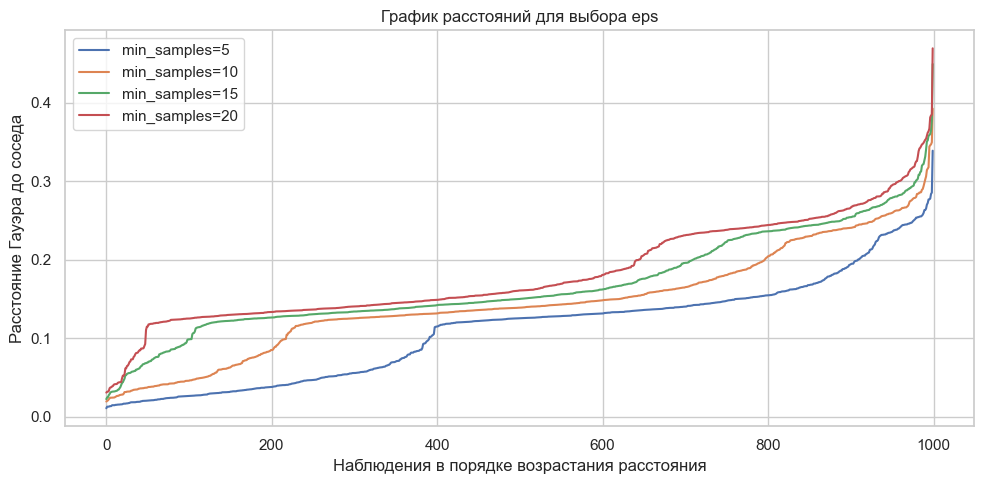

In [9]:
MIN_SAMPLES_GRID = [m for m in (5, 10, 15, 20) if m <= len(X)]
if not MIN_SAMPLES_GRID:
    raise ValueError("Для выбранной сетки необходимо минимум 5 наблюдений")

sorted_distances = np.sort(D, axis=1)
k_distances = {m: sorted_distances[:, m - 1] for m in MIN_SAMPLES_GRID}

fig, ax = plt.subplots(figsize=(10, 5))
for m, distances in k_distances.items():
    ax.plot(np.sort(distances), label=f"min_samples={m}")
ax.set(xlabel="Наблюдения в порядке возрастания расстояния",
       ylabel="Расстояние Гауэра до соседа",
       title="График расстояний для выбора eps")
ax.legend()
plt.tight_layout()
plt.show()

In [10]:
def evaluate_clustering(distance_matrix, labels):
    """Оценка в исходной метрике; метка -1 всегда исключается из silhouette."""
    labels = np.asarray(labels)
    assigned = labels != -1
    _, sizes = np.unique(labels[assigned], return_counts=True)
    n_clusters = len(sizes)
    silhouette = np.nan
    if 2 <= n_clusters < assigned.sum():
        silhouette = float(silhouette_score(
            distance_matrix[np.ix_(assigned, assigned)],
            labels[assigned], metric="precomputed"
        ))
    return {
        "n_clusters": n_clusters,
        "noise_fraction": float((~assigned).mean()),
        "min_cluster_size": int(sizes.min()) if sizes.size else 0,
        "max_cluster_size": int(sizes.max()) if sizes.size else 0,
        "largest_cluster_fraction": float(sizes.max() / sizes.sum()) if sizes.size else np.nan,
        "silhouette": silhouette,
    }

rows = []
for min_samples in MIN_SAMPLES_GRID:
    eps_grid = np.unique(np.r_[
        np.linspace(0.03, 0.30, 55),
        np.quantile(k_distances[min_samples], [0.1, 0.25, 0.5, 0.75, 0.9, 0.95])
    ])
    for eps in eps_grid[eps_grid > 0]:
        trial_labels = DBSCAN(
            eps=float(eps), min_samples=min_samples, metric="precomputed"
        ).fit_predict(D)
        rows.append({"eps": float(eps), "min_samples": min_samples,
                     **evaluate_clustering(D, trial_labels)})

search_results = pd.DataFrame(rows)
print(f"Проверено сочетаний параметров: {len(search_results)}")
display(search_results.sort_values(
    ["silhouette", "noise_fraction"], ascending=[False, True], na_position="last"
).head(15).round(4))

Проверено сочетаний параметров: 244


,eps,min_samples,n_clusters,noise_fraction,min_cluster_size,max_cluster_size,largest_cluster_fraction,silhouette
127,0.0550,15,2,0.951,20,29,0.5918,0.8355
190,0.0650,20,2,0.950,21,29,0.5800,0.8313
191,0.0700,20,2,0.950,21,29,0.5800,0.8313
192,0.0750,20,2,0.950,21,29,0.5800,0.8313
193,0.0800,20,2,0.950,21,29,0.5800,0.8313
194,0.0850,20,2,0.950,21,29,0.5800,0.8313
195,0.0900,20,2,0.950,21,29,0.5800,0.8313
196,0.0950,20,2,0.950,21,29,0.5800,0.8313
197,0.1000,20,2,0.950,21,29,0.5800,0.8313
198,0.1050,20,2,0.950,21,29,0.5800,0.8313


## Выбор модели

Используем максимальный silhouette среди вариантов, где шум составляет не более
40%. Этот порог — настраиваемое исследовательское ограничение для сохранения
достаточного числа клиентов в кластерах, а не свойство DBSCAN.
Сравнение silhouette при разных наборах нешумовых точек приблизительно.

Если подходящего варианта нет, явно сообщаем об этом: не выбираем произвольное
разбиение вместо него. Высокий silhouette сам по себе не означает полезную
сегментацию: отдельно проверяем дисбаланс размеров кластеров.

In [11]:
MAX_NOISE_FRACTION = 0.40
candidates = search_results.loc[
    search_results["silhouette"].notna()
    & (search_results["noise_fraction"] <= MAX_NOISE_FRACTION)
].sort_values(["silhouette", "noise_fraction", "eps", "min_samples"],
              ascending=[False, True, True, True])

if candidates.empty:
    raise ValueError(
        "В сетке нет разбиения хотя бы на два кластера при заданной доле шума. "
        "Изучите search_results и пересмотрите сетку или MAX_NOISE_FRACTION."
    )

best = candidates.iloc[0]
model = DBSCAN(eps=float(best["eps"]), min_samples=int(best["min_samples"]),
               metric="precomputed")
labels = model.fit_predict(D)
metrics = evaluate_clustering(D, labels)

clustered_df = df.copy()
clustered_df["cluster"] = labels
clustered_df["point_type"] = np.where(labels == -1, "noise", "border")
clustered_df.loc[clustered_df.index[model.core_sample_indices_], "point_type"] = "core"

print(f"Выбрано: eps={model.eps:.4f}, min_samples={model.min_samples}")
display(pd.Series(metrics, name="DBSCAN").to_frame().round(4))
display(clustered_df.groupby(["cluster", "point_type"]).size().unstack(fill_value=0))
if metrics["largest_cluster_fraction"] > 0.95:
    print("Внимание: более 95% нешумовых наблюдений попали в один кластер. "
          "Такое разбиение сильно несбалансировано.")

Выбрано: eps=0.1500, min_samples=5


,DBSCAN
n_clusters,2.0000
noise_fraction,0.1050
min_cluster_size,3.0000
max_cluster_size,892.0000
largest_cluster_fraction,0.9966
silhouette,0.2379


point_type,border,core,noise
cluster,,,
-1,0,0,105
0,127,765,0
1,2,1,0


Внимание: более 95% нешумовых наблюдений попали в один кластер. Такое разбиение сильно несбалансировано.


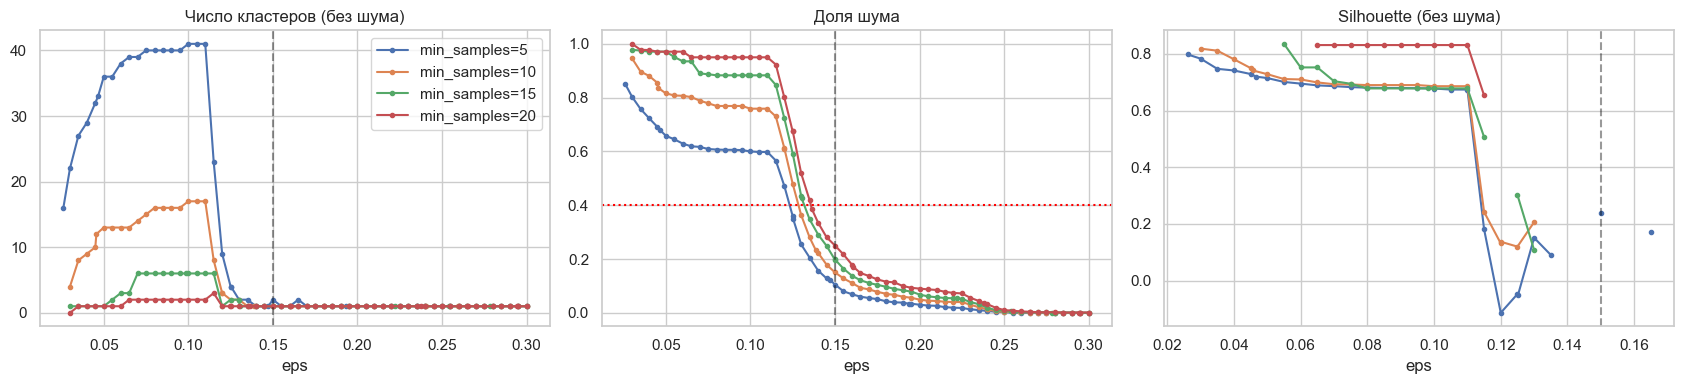

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for m, group in search_results.groupby("min_samples"):
    group = group.sort_values("eps")
    for ax, metric, title in zip(
        axes, ["n_clusters", "noise_fraction", "silhouette"],
        ["Число кластеров (без шума)", "Доля шума", "Silhouette (без шума)"]
    ):
        ax.plot(group["eps"], group[metric], marker=".", label=f"min_samples={m}")
        ax.set(xlabel="eps", title=title)
for ax in axes:
    ax.axvline(model.eps, color="black", linestyle="--", alpha=0.4)
axes[0].legend()
axes[1].axhline(MAX_NOISE_FRACTION, color="red", linestyle=":")
plt.tight_layout()
plt.show()

## Визуализация и профили кластеров

t-SNE строится по той же матрице Гауэра; метки кластеров в построении проекции
не участвуют. Это иллюстрация: расстояния и плотности на плоскости искажены,
поэтому модель и silhouette вычислялись до проекции. Шум (`-1`) отмечен серым.
В профилях он показан отдельно и не считается кластером.

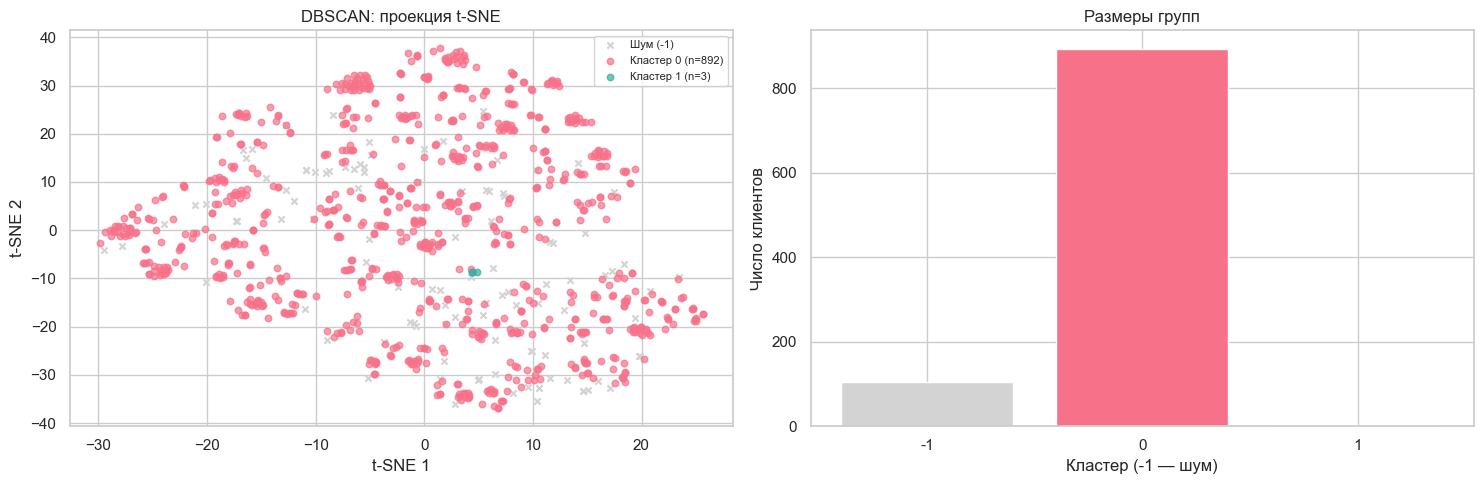

In [13]:
embedding = TSNE(
    n_components=2, metric="precomputed", init="random",
    perplexity=min(30, len(X) - 1), learning_rate="auto",
    random_state=RANDOM_STATE
).fit_transform(D)

cluster_ids = sorted(set(labels) - {-1})
colors = dict(zip(cluster_ids, sns.color_palette("husl", len(cluster_ids))))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
noise = labels == -1
if noise.any():
    axes[0].scatter(*embedding[noise].T, c="lightgray", s=20, marker="x", label="Шум (-1)")
for cluster_id in cluster_ids:
    mask = labels == cluster_id
    axes[0].scatter(*embedding[mask].T, color=colors[cluster_id], s=22, alpha=0.7,
                    label=f"Кластер {cluster_id} (n={mask.sum()})")
axes[0].set(title="DBSCAN: проекция t-SNE", xlabel="t-SNE 1", ylabel="t-SNE 2")
axes[0].legend(fontsize=8)

sizes = clustered_df["cluster"].value_counts().sort_index()
axes[1].bar(sizes.index.astype(str), sizes.values,
            color=["lightgray" if k == -1 else colors[k] for k in sizes.index])
axes[1].set(title="Размеры групп", xlabel="Кластер (-1 — шум)", ylabel="Число клиентов")
plt.tight_layout()
plt.show()

,count,share
cluster,,
-1,105,0.105
0,892,0.892
1,3,0.003


Age        Credit amount          Duration       
          mean median          mean   median     mean median
cluster                                                     
-1       41.92   40.0       4945.85   3622.0    27.32   24.0
 0       34.78   32.0       3047.16   2248.0    20.14   18.0
 1       41.33   42.0      11291.00  12579.0    23.00   24.0

,cluster,feature,most_common,share
0,-1,Sex,female,0.514
1,-1,Job,3,0.305
2,-1,Housing,own,0.381
3,-1,Saving accounts,little,0.362
4,-1,Checking account,moderate,0.448
5,-1,Purpose,education,0.200
6,0,Sex,male,0.716
7,0,Job,2,0.673
8,0,Housing,own,0.754
9,0,Saving accounts,little,0.630


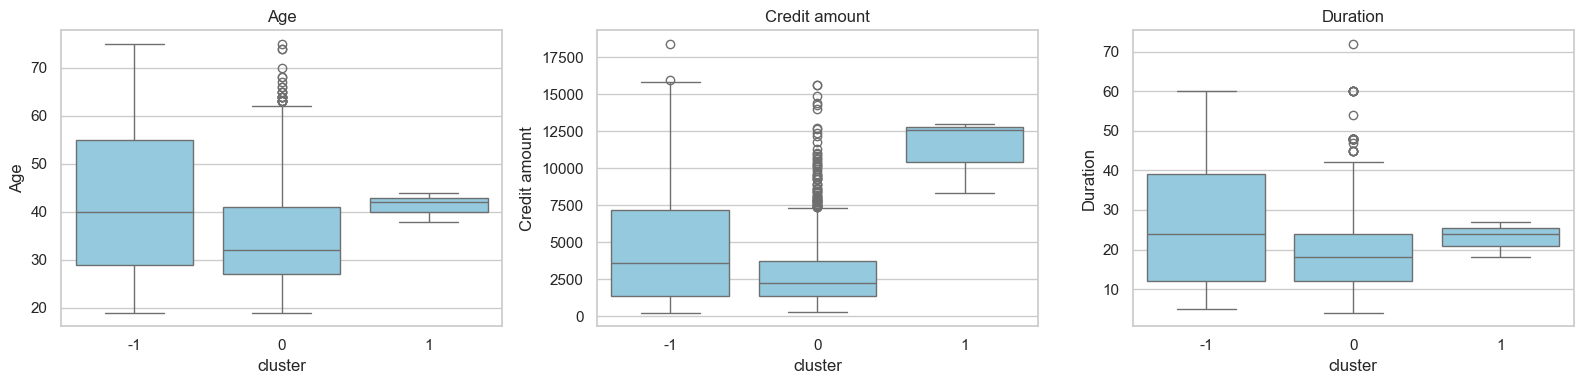

In [14]:
numeric_profile = clustered_df.groupby("cluster")[num_cols].agg(["mean", "median"])
cluster_summary = clustered_df.groupby("cluster").size().rename("count").to_frame()
cluster_summary["share"] = cluster_summary["count"] / len(clustered_df)
display(cluster_summary.round(3))
display(numeric_profile.round(2))

profile_data = X[cat_cols].copy()
profile_data["cluster"] = labels
category_rows = []
for cluster_id, group in profile_data.groupby("cluster"):
    for col in cat_cols:
        shares = group[col].value_counts(normalize=True)
        category_rows.append({"cluster": cluster_id, "feature": col,
                              "most_common": shares.index[0], "share": shares.iloc[0]})
categorical_profile = pd.DataFrame(category_rows)
display(categorical_profile.round(3))

fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=clustered_df, x="cluster", y=col, ax=ax, color="skyblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [16]:
assigned_sizes = clustered_df.loc[clustered_df["cluster"] != -1, "cluster"].value_counts()
interpretation = (
    "Почти все нешумовые клиенты оказались в одной группе. Малые группы требуют "
    "отдельной проверки; выбранный максимум silhouette не подтверждает полезную сегментацию."
    if metrics["largest_cluster_fraction"] > 0.95 else
    "Для оценки полезности групп сравните их размеры и профили признаков."
)
display(Markdown(
    f"### Выводы\n\n"
    f"При `eps={model.eps:.4f}` и `min_samples={model.min_samples}` получено "
    f"**{metrics['n_clusters']} кластера(ов)**; шум — **{metrics['noise_fraction']:.1%}** "
    f"({int((labels == -1).sum())} клиентов). Silhouette без шума: "
    f"**{metrics['silhouette']:.3f}**. Размеры кластеров: "
    f"**{', '.join(map(str, assigned_sizes.tolist()))}**.\n\n"
    f"{interpretation} Графики подбора показывают чувствительность к параметрам. "
    "Вывод зависит от равных весов признаков и представления пропусков категорией Unknown. "
    "Шум означает отсутствие достаточно плотного окружения при выбранных параметрах; "
    "это не метка кредитного риска.\n\n"
    "Метки доступны в `clustered_df`, все результаты подбора — в `search_results`. "
    "При необходимости сохраните таблицу командой "
    '`clustered_df.to_csv("german_credit_dbscan.csv", index=False)`.'
))

### Выводы

При `eps=0.1500` и `min_samples=5` получено **2 кластера(ов)**; шум — **10.5%** (105 клиентов). Silhouette без шума: **0.238**. Размеры кластеров: **892, 3**.

Почти все нешумовые клиенты оказались в одной группе. Малые группы требуют отдельной проверки; выбранный максимум silhouette не подтверждает полезную сегментацию. Графики подбора показывают чувствительность к параметрам. Вывод зависит от равных весов признаков и представления пропусков категорией Unknown. Шум означает отсутствие достаточно плотного окружения при выбранных параметрах; это не метка кредитного риска.

Метки доступны в `clustered_df`, все результаты подбора — в `search_results`. При необходимости сохраните таблицу командой `clustered_df.to_csv("german_credit_dbscan.csv", index=False)`.